# **CS781 Assignment 1** [3890 Marks]

#**Enter your details below:**

Full Name: YourName

Roll No: 007

Email: youremail@iitk.ac.in

**Deadline: 28-Aug-2026 11:59 PM**



#Instructions for creating huggingface token



1. Create hugging face account and on the top right corner select your profile and click on settings.
2. On the left side of the screen click on "Acess Tokens" option then click on "Create Token" option.
3. Choose the "Write" option, give the name for the token and click on Create Token option.

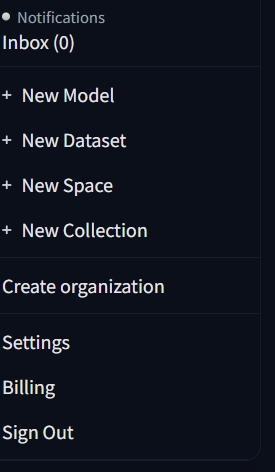
<br>
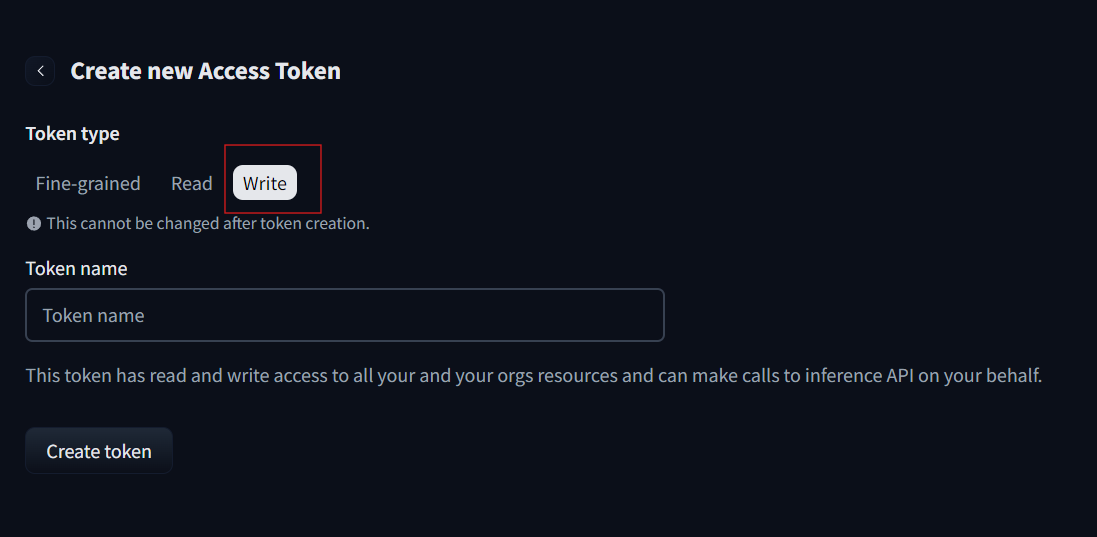

# Initial Setup
1. Install the `datasets` library made by huggingface to download and interact with the data. Install the `indic-nlp-library` which contains some relevant functions for processing Indian languages.
2. Import the `load_dataset` method from `datasets`
3. Copy and paste the huggingface token you generated above to start using the assingment data
4. The repository id of the data stored in https://huggingface.co/datasets/Exploration-Lab/CS781
5. Import `nltk` (natural language toolkit) library for processing english language data.
6. English consists of many "stopwords" including the aritcles like "a", "an", "the" and joining words like "with", "and" etc. Typical NLP tasks filter out these "stopwords" as they do not carry significant meaning to understand the sentence. So let's download all the stopwords and keep them ready for use.

In [ ]:
!pip install datasets indic-nlp-library
!pip install --upgrade datasets
from datasets import load_dataset
# hf_token = "xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx" # Put your huggingface token here
hf_token = ""
REPO_ID = "Exploration-Lab/CS781" # this is the repository ID where the assignment data is stored

import nltk
nltk.download("stopwords")

import os
from collections import Counter

import pandas as pd
import numpy as np

import spacy
spacy.prefer_gpu()
nlp = spacy.load("en_core_web_sm")

from tqdm import tqdm
tqdm.pandas()


# **Question 1: Zipf’s Law [Total 580 Marks]**








## Introduction

In this question, you will explore Zipf's Law by analyzing the frequency distribution of words in two languages: English and Hindi. Your task is to apply statistical analysis, plot frequency vs. rank curves, and derive insights from your findings.

## Objectives

- Understand and analyze Zipf's Law in the context of different languages.
- Implement methods to handle large corpora efficiently.
- Calculate the parameter "k" in the power-law relationship.
- Plot frequency vs. rank and log-log plots to visualize the relationship.
- Make detailed observations and interpretations of the results.

## Background: What is Zipf's Law?

Zipf’s Law states that in a large corpus of natural language, the frequency of any word is inversely proportional to its rank in the frequency table. This implies that frequency and rank are related by a power law.


Zipf's Law can be expressed as:
$$
f(r) = \frac{C}{r^k}
$$
Where:
- $ f(r) $ is the frequency of the word at rank $ r $.
- $ r $ is the rank of the word (1 for the most frequent word, 2 for the second most frequent, etc.).
- $ C $ is a constant that depends on the distribution of the frequencies.
- $ k $ is a parameter that decides the power law relationship.

For example, for some given constant "$k$", the most frequent word will appear roughly twice as often as the second most frequent word. The second most frequent word will appear approximately three times as often as the third most frequent word, and so on.



## **Question 1: Analyzing Zipf’s Law Across Multiple Languages**

## Instructions and Guidelines
We will be developing a modular code for solving Question 1. Hence you will have to fill in the missing code pieces and at the end of Question 1 there would be a `main` function that would call all the relevant functions to solve the tasks given below.

Importing relevant libraries.

In [ ]:
import math
import matplotlib.pyplot as plt
from indicnlp.tokenize import indic_tokenize
from collections import defaultdict

### 1. Dataset and Language Selection [100 marks]

You are provided with datasets for two languages (Dataset is available  on [huggingface](https://huggingface.co/datasets/Exploration-Lab/CS781/blob/main/Assignment-1/train.parquet)), comprising of English and Hindi.
**Tasks**
1. Load the dataset for each language from huggingface
2. Preprocess the text to tokenize it into words. Ensure that you properly handle different languages using appropriate tokenizers like those available in the Indic library. Feel free to refer to the [documentation](https://anoopkunchukuttan.github.io/indic_nlp_library/) to write the code stubs in the following sections.

In [ ]:
dataset = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=token)
dataset

### 2. Word Frequency Analysis [50 marks]

Once you have tokenized the text:

- **Task**: Calculate and store (using appropriate data-structure) the frequency of each word in each of the corpus.

### 3. Word Frequency Analysis (Contd.) [50 marks]

- **Task:** Rank the words in the reverse order of their frequencies. Hence the most popular word should be first and the least popular word should be last

### 4. Plotting Zipf's Law Curves [100 + 100 marks]

You are required to plot two types of curves:

1. **Rank vs Frequency Curve**:
   - **Task**: Rank the words by their frequency and plot a graph with the rank on the x-axis and the frequency on the y-axis.
   
2. **Log Rank vs Log Frequency Curve**:
   - **Task**: Transform the ranks and frequencies to their logarithmic (natural logarithm) values and plot a graph with log rank on the x-axis and log frequency on the y-axis.
   
   - This plot will help you observe the linear relationship that typically characterizes Zipf’s Law.



### 5. Finding the Parameter "k" [100 marks]

Zipf's Law involves a parameter "k" that characterizes the steepness of the frequency distribution curve.

- **Task**:  From the log-plot calculate the value of $ k $ for each language. (HINT: you could use linear regression on log plot.)



### 6. Observations and Interpretations [20 + 20 + 20 + 20 marks]

- **Task**: Write a detailed observation for each language, addressing the following points:
  - How closely does the word frequency distribution follow Zipf’s Law?
  - What are the values of $ k $ for each language? Are they close to 1?
  - Compare the distributions across different languages. Are there any noticeable differences or patterns?
  - Discuss any challenges you faced, especially with large corpora, and how you overcame them.


### `main` function

The `main` function calls all the other functions above to analyse the data and develop the plots for results and observations.

Try to change the language and see how the results vary.


In [ ]:
def main():

    dataset = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=token)
    language = "hi" # or "en"
    process_Corpus(dataset, language)
if __name__ == "__main__":
    main()

### 7. Reporting Results

Compile your results, including the plots and observations.
- Make sure you write all observations in a clear, well-organized manner, thoroughly explaining your methodology, findings, and conclusions. Include your plots, the calculated values of $ k $, and any insights or anomalies you observed.

Here are some reading resources for Zipf's law: \
[https://en.wikipedia.org/wiki/Zipf%27s_law](https://en.wikipedia.org/wiki/Zipf%27s_law) \
[https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4176592/](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4176592/)

---

# **Question 2 : N-Gram models [Total: 900 Marks]**

**Introduction**

Language models are statistical models that give out the probability distribution of a sentence (sequence of tokens). They rely on the joint probability distribution of the tokens in the sentence.

For example, let us calculate the probability of the sentence "Monza is a fast track on the F1 GP". Then the probability of the sentence is given as:
$$
P = P(\text{<s>Monza is a fast track on the F1 GP</s>})
$$
Where `<s>` and `</s>` are predefined start and end tokens respectively.

We can then divide the sentence into tokens and use the chain rule of probability to make the calculations easier.
$$
P = P(\text{Monza|<s>}).P(\text{is|<s>Monza}).P(\text{a|<s>Monza is}).P(\text{fast|<s>Monza is a}) ... .P(\text{</s>|<s>Monza is a fast track on the F1 GP})
$$

Learning the joint probability distirbution is much more difficult and hence usually we have Markov Assumption (https://en.wikipedia.org/wiki/Discrete-time_Markov_chain). The main idea is the current token only depend on the previous token and you can ignore the history before the previous token. Given the Markov Assumption, we have:

$$
P(\text{is|<s>Monza}) = P(\text{is|Monza}) \\
P(\text{a|<s>Monza is}) = P(\text{a|is}) \\
P(\text{fast|<s>Monza is a}) = P(\text{fast|a}) \\
... \\
P(\text{</s>|<s>Monza is a fast track on the F1 GP}) = P(\text{</s>|GP})
$$

Hence, we can write the probability of the complete sentence as

$$
P(\text{<s>Monza is a fast track on the F1 GP</s>}) = \\P(\text{Monza|<s>}).P(\text{is|Monza}).P(\text{a|is})...P(\text{</s>|GP})
$$

Above we made 1st order Markov Assumption, giving us a **BiGram Language Model**. Similarly, we can make $(n-1)^{st}$ order Markov assumption, giving us  **n-gram Language Model**

In general using n-gram model, the probability of a sentence $s$ is given as:
$$
P(s) = \prod{P(w_n|w_{1} w_{2} w_{3} w_{4} ... w_{n-1})}
$$

Can you think and write down the sentence probability  expression for a unigram model?

#### Reading Materials
N-gram language models refer to language models that work on n-tokens simultaneously. Here are some reading resources to learn about n-gram language models:
- https://web.stanford.edu/~jurafsky/slp3/3.pdf
- https://web.cs.hacettepe.edu.tr/~ilyas/Courses/CMP711/lec03-LanguageModels.pdf

-----------------------------





## Instructions

**TASK**: We aim to create a n-gram model using words from a parallel English-Hindi corpus. Then we predict the probability of a new sentence using unigram, bigram, trigram and tetragram language models.

**OBJECTIVE**: Learn to build unigram, bigram,  trigram and tetragram language models. Usually this method is applied to a single language, but here we are applying it to both languages simultaneously.

#### Instructions:
This code is similar to Question 1 and 2 where we will develop multiple functions individually and connect them to each other using the `main` function at the end of the question.

In [ ]:
from huggingface_hub import hf_hub_download
import pandas as pd
from datasets import load_dataset, Dataset

def load_data():
    """
    Loading the data from huggingface

    Returns: a dataframe containing the text from wikipedia mini corpus.
    (Follow the huggingface links)
    """

    # Download the Parquet file
    dataset = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=token)
    return dataset
dataset = load_data()

In [ ]:
dataset

## Step-1: Unigram, Bigram, Trigram and Tetragram Probabilities: **[500 + 50 + 20 + 60 + 10 + 20 = 660 marks]**

Compute unigram, bigram and trigram probabilities.
1. Have pass over the corpus collecting and updating unigram, bigram and trigram counts. Using counts calculate unigram, bigram and trigram probabilities. For example, bigram probability is given by:

$p(w_{i+1} = t \mid w_{i} = t^{'}) = \frac{C(w_{i+1} = t, w_{i} = t^{'})}{\sum_{k \in V} C(w_{i+1} = k, w_{i} = t^{'})}$

Here, $V$ is the vocabulary and $C(w_{i+1} = t, w_{i} = t^{'})$ is the count of $(t, t^{'})$ co-occurring together.

2. Can you prove the above probability formula for bigram and similarly prove the probability formula for tri-gram and tetra-gram.

3. Find the most frequent unigrams, bigrams, trigrams and tetragrams.
4. Plot the bar charts of the 10 most frequent unigrams, bigrams, trigrams and tetragrams.
5. Do you observe any interesting patterns in the plots?
6. Do you see any repeated tags in unigram, bigram, trigrams and tetragrams frequencies? If so, then what do you make of it?



## Step-2: Sentence Probability: **[100 + 100 marks]**

1. Pick up 1000 random sentences from the corpus. Calculate the sentence probability separately using unigram, bigram, trigram and tetragram models. What do you observe? Is the probability same for unigram, bigram, trigram and tetragram models?
2. Given a sentence such as **"Lewis Hamilton is a"**, can you predict the next word that can come after "is a"? Try to predict separately with using unigram, bigram, trigram amd tetragram models. Which model gives the best prediction?

Given the reliance of n-gram models on the presence of sequential tokens in the training data, there exists a situation where the queried n-gram is not present in the training data. For example, there may be a trigram sequence that is not there in the trigram model or in the training data then how can one calculate the sentence probability? Now we look at 3 popular methods to handle this situation.

1. **Backoff Model:** When predicting the sentence probability of a target sentence using an n-gram model we can switch to an (n-1)-gram model if the queried sequence is not there in the n-gram model. For example, if `[Monza, is, in]` is not a part of the tri-gram model we can predict the probability of the above phrase by taking the product of the bi-gram probabilities of `[Monza, is]` and `[is, in]`. In a backoff-model one can keep repeating this process till we reach a uni-gram model. However, backoff is only applied to the n-gram sequence that is not found in the n-gram model, while the probability of the rest of the sequence is calculated as is. Please refer to [Lecture-3 Language models](https://web.cs.hacettepe.edu.tr/~ilyas/Courses/CMP711/lec03-LanguageModels.pdf) for a deeper understanding of backoff models.
2. **Smoothing:** When calculating the n-gram sequence probabilty of new/unknown (not part of training data or model) sequence, we can replace $0$ with a value $\epsilon << 1$, to prevent the probability from collapsing to $0$. This method is called smoothing.
3. **Linear Interpolation:** N-gram probability of the next word can also be computed as a linear sum of tetragram, trigram, bigram and unigram probabilities.
$$
P(w_n \mid w_{n-1}, w_{n-2}, w_{n-3}) = \lambda_1 P(w_n \mid w_{n-1}, w_{n-2}, w_{n-3}) + λ_2P(w_n \mid w_{n-1}, w_{n-2}) + λ_3P(w_n \mid w_{n-1}) + λ_4P(w_n)
$$
Under the constraint that $\lambda_1 + \lambda_2 + \lambda_3 + \lambda_4 = 1$. The $\lambda$ values can be estimated by dividing the data into 2 parts calling them `train` and `val` splits.

## Step-3: Analytical Questions [20 x 2 = 40 Marks]

1. **What other smoothing methods do you know? Can they be applied here?**

---Write your answer here---

2. **Can you do a cross-language comparison of unigram, bigram, trigram and tetragram models without training them again?**

---Write your answer here---

---

# **Question 3 : Word2vec [Total 1610 Marks]**

## **1. Introduction to Word2Vec**

## **Objective**
In this assignment, you will implement **Word2Vec (CBOW)** from scratch in PyTorch, using **three different strategies**:

1. **Full Softmax**
2. **Negative Sampling**
3. **Hierarchical Softmax** (Huffman-tree based)

You will train each variant on **two corpora**: **Hindi** and **English**

You are **not** allowed to use `gensim` or any pre-built Word2Vec implementation. You must write the CBOW model, the training loop, the Huffman tree, and the negative sampler yourself, in PyTorch/NumPy.

By the end of this part, you will:
*   Understand the concept of distributed word embeddings.
*   Learn about **CBOW** architectures.
*   Implement custom PyTorch `Dataset` classes for vectorized data loading.
*   Build a PyTorch `nn.Module` for Hierarchical Softmax, utilizing `torch.bmm` for batch matrix operations.
*   Train Word2Vec on a text corpus using the **Adam optimizer**.
*   Evaluate embeddings on an **analogy task** using a provided dataset.

---

### **What is Word2Vec?**
Word2Vec is a shallow neural network that learns **dense vector representations of words** such that semantically similar words lie close together in the embedding space.

The key idea: instead of representing words as one-hot vectors, we represent them as low-dimensional **embeddings** learned by predicting context words from a target word (or vice versa).

---
### CBOW Architecture

The **CBOW model** in Word2Vec learns word embeddings by predicting a center (target) word given its surrounding context words. It avoids one-hot vectors using index-based embedding lookup, making it both space- and time-efficient.

---

#### Visual Overview

**1. CBOW Model Structure**  
![CBOW Model Structure](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*wrlax7j2AHUsFIgcpagLHg.png)




---

#### Intuition

Sentence:  
**"The cat sat on the mat"**, with **window size = 2**

If target word = `"cat"`, context = `["The", "sat"]`  
→ Training pairs:
- (`["The", "sat"]` → `cat`)

#### Architecture and Training Flow (with Index-based Input)

Let:  
- $ V $: size of the vocabulary  
- $ d $: embedding dimension  
-   C = $ c_1, c_2, \dots, c_m $ : list of context word indices  
-  $ t $: index of the target word  
-  $ E \in {R}^{V \times d} $ : input embedding matrix  
-  $ E' \in {R}^{V \times d} $ : output embedding matrix

Each context word $ c_i \in C $ is used to lookup a vector from $ E $, which are then averaged to form a single context embedding.

---

#### Step-by-Step Computation:

1. **Input**: Integer IDs of context words  C = $ {c_1, c_2, \dots, c_m} $

2. **Embedding Lookup**:

$$
h = \frac{1}{m} \sum_{i=1}^{m} E[c_i] \in \mathbb{R}^d
$$

3. **Score for Target Word $ t $**:

$$
\text{score}(t) = h^\top E'[t]
$$

4. **Softmax over Vocabulary**:

$$
P(w_t \mid \text{context}) = \frac{\exp(h^\top E'[t])}{\sum_{w=1}^{V} \exp(h^\top E'[w])}
$$

---

#### Objective Function

Given **context words** $ \{w_{t-k}, \dots, w_{t-1}, w_{t+1}, \dots, w_{t+k}\} $, the CBOW model aims to **predict the center word** \( w_t \).

$$
{L}_{\text{CBOW}} = \log P(w_t \mid w_{t-k}, \dots, w_{t-1}, w_{t+1}, \dots, w_{t+k})
$$

where


| Term &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;    | Description |
|---------|-------------|
| $ {L}_{\text{CBOW}} $ | The **log-likelihood** objective for predicting the center word $ w_t $ given its surrounding context words. |
| $ k $ | The **window size**, which defines how many words before and after the target word are used as context. |
| $ c_i $ | The **context word index** used for embedding lookup. |
| $ w_t $ | The **center word** (target word) to be predicted. |
| $ P(w_t \mid \text{context}) $ | The **conditional probability** of $ w_t $ being the correct word, given the context. |
| $ log P(w_t \mid \text{context}) $ | The **log-probability** of predicting $ w_t $ correctly given its context. |


---

#### Parameters Learned

- $ E \in {R}^{V \times d} $: Embedding matrix (input)
- $ E' \in {R}^{V \times d} $: Output matrix (used for prediction)

**Note**: Final embeddings are typically taken from matrix $ E $

---

### Summary

- **Input**: Integer indices of context words  
- **Output**: Predict index of target (center) word  
- **Lookup**: Embed each context word, then average  
- **Train**: With softmax or negative sampling  
- **Goal**: Words that appear in similar contexts should learn similar vector representations

---

### **Negative Sampling in Word2Vec**

---

#### Why Not Full Softmax?

In the original CBOW formulation, the softmax function is used to compute the probability of the target word given its context:

$$
P(w_t \mid \text{context}) = \frac{\exp(u_{w_t}^\top h)}{\sum_{w=1}^{V} \exp(u_w^\top h)}
$$

Where:
- $ h = \frac{1}{m}\sum_{i=1}^m E[c_i] $: averaged embedding of the context words
- $ u_{w_t} $: output embedding of the target word $ w_t $
- $ V $: vocabulary size

**Problem**:  
The denominator sums over **all words in the vocabulary** $ V $ — this is extremely slow for large corpora.

---

#### Solution: Negative Sampling

Instead of updating **all output weights**, **update only a small number of "negative samples"** along with the one positive pair.

---


#### Intuition

- For each training example (context $ C $, target $ w_t $):
  - Treat $ w_t $ as a **positive example**
  - Sample $ k $ random words $ \{w_1^{'}, w_2^{'}, ..., w_k^{'}\} $ from the vocabulary — these are **negative samples**
- The goal:
  - **Maximize** the probability of the real target word $ w_t $ given context $ h $
  - **Minimize** the probability of the negative samples $ w_i^{'} $ given the same context $ h $

---

#### Loss Function

For a context $C = \{c_1, \dots, c_m\}$ (averaged into $h$) and target word $w_t$, the **negative sampling loss** is:

$$
{L}_{\text{negative-sampling}} = -\log \sigma(u_{w_t}^\top h) - \sum_{i=1}^{k} \log \sigma(-u_{w_i^{'}}^\top h)
$$

Where:
- $ \sigma(x) = \frac{1}{1 + \exp(-x)} $  : sigmoid function
- $ h = \frac{1}{m}\sum_{i=1}^m E[c_i] $: averaged context embedding (from $E$)
- $ u_w $: output embedding of word $ w $ (from $E'$)
- $ w_t $: actual target/center word (positive sample)
- $ w_i^{'} $: i-th negative sample, sampled as a **fake target word**
- $ k $: number of negative samples

---

#### Training Workflow (Step-by-Step)

1. **Input**: context word indices $ C = \{c_1, \dots, c_m\} $, target word $ w_t $
2. **Get embeddings**:
   - $ h = \frac{1}{m}\sum_i E[c_i] \in {R}^d $ — averaged context vector from input matrix $ E $
   - $ u_{w_t} \in {R}^d $ from output matrix $ E'$
3. **Sample** $ k $ random words from vocabulary as negative (fake target) samples
4. **Compute loss** using the formula above
5. **Backpropagate** and update only:
   - $ E[c_i] $ for each $ c_i \in C $ (via $h$)
   - $ u_{w_t} $
   - $ u_{w_i^{'}} $ for all $ i \in [1, k] $
---




#### Why It Works

- Drastically reduces **computation time**.
- Still allows the model to learn **good semantic embeddings**.
- Scales to **billions of tokens** and **millions of words**.
- Enables **mini-batch training** with sparse updates.


---
### **Hierarchical Softmax in Word2Vec**

---

####  Why Another Alternative to Softmax?

Like Negative Sampling, **Hierarchical Softmax (HS)** addresses the computational inefficiency of the full softmax, especially for large vocabularies.

**Key Idea**:  
 Instead of scoring all words in the vocabulary, we build a **binary tree** and compute the probability of a word by traversing the path from the **root to that word's leaf**.

---

#### How Hierarchical Softmax Works

1. Build a **binary tree** where:
   - **Leaves** represent vocabulary words.
   - **Internal nodes** make **binary decisions**: left/right.

2. Each word is uniquely identified by a **path from the root to a leaf**.

3. The model:
   - Learns vector representations for each **internal node**.
   - Predicts the correct **binary decision** at each node in the path.

---

#### Example

Say the word **"sat"** is located along this binary path:
```
Root → Left → Right → Left → [sat]
```

We must predict:
- Step 1: Go **Left**
- Step 2: Go **Right**
- Step 3: Go **Left**

So the model predicts **a sequence of decisions** — **not** the word directly.

---

#### Mathematical Formulation

Let:
- $ w $ : target word to predict
- $ C = \{c_1, \dots, c_m\} $ : context word indices
- $ h = \frac{1}{m}\sum_{i=1}^m E[c_i] $ : averaged context embedding
- $ L(w) $ : length of the binary path to $ w $
- $ n_i $ : the $ i^{th} $ internal node along the path to $ w $
- $ s_i \in \{+1, -1\} $: direction at node $ n_i $ (+1 = left, -1 = right)
- $ v_{n_i} $ : vector associated with internal node $ n_i $
- $ \sigma(x) = \frac{1}{1 + \exp(-x)} $

Then:

$$
P(w \mid \text{context}) = \prod_{i=1}^{L(w)} \sigma\left( s_i \cdot v_{n_i}^\top h \right)
$$

---

#### Loss Function

For predicting target word $ w $ given context $ C $, the **loss is**:

$$
{L}_{\text{HS}} = - \sum_{i=1}^{L(w)} \log \sigma\left( s_i \cdot v_{n_i}^\top h \right)
$$

- Similar to Negative Sampling, the model uses **sigmoid** activations at each node, applied to the averaged context vector $h$ rather than a single word's embedding.
- Each decision is treated as a **binary classification task**.

---


#### Summary

- Hierarchical Softmax is a tree-based approximation to full softmax.
- Words are predicted by following binary paths.
- Each step in the path is trained via sigmoid + binary cross-entropy.
- Enables fast, full-vocab prediction with logarithmic complexity.

---



## **2. Task Explanation**

### **Goal**:

* Implement **Word2Vec (CBOW)** using **PyTorch**, train on each corpora separately (English and Hindi).
* Use the below code to download the dataset for training on each corpus.
  ```python

  from datasets import load_dataset

  train = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=token)

  test_en = load_dataset("Exploration-Lab/CS781", data_files={"en": "Assignment-1/analogy_test_en.parquet"}, split="en", token=token)
  test_hi = load_dataset("Exploration-Lab/CS781", data_files={"hi": "Assignment-1/analogy_test_hi.parquet"}, split="hi", token=token)
  ```


- After training your Word2Vec model, save the learned embeddings along with the vocabulary mappings using `pickle` (you must create total 6 embeddings i.e., for english and hindi using all three strategies):

  ```python
  import pickle

  with open("en_embeddings.pkl", "wb") as f:
      pickle.dump({
          "embeddings": embeddings,     # numpy  array of shape (vocab_size, embedding_dim)
          "vocab": vocab.itos,          # list: index → token
          "stoi": vocab.stoi            # dict: token → index
      }, f)

  with open("hi_embeddings.pkl", "wb") as f:
      pickle.dump({
          "embeddings": embeddings,     # numpy  array of shape (vocab_size, embedding_dim)
          "vocab": vocab.itos,          # list: index → token
          "stoi": vocab.stoi            # dict: token → index
      }, f)
  ```

- Evaluate the learned embeddings using a word analogy task and generate a result CSV file with predictions.


**Implementation Workflow Tips(not neccessary to follow these but suggested):**

- Test Small First: Always test your custom PyTorch Dataset, DataLoader, and model pipelines on a very small subset (e.g., a few hundred rows) to catch code and logic errors instantly.

- Scale Up to the Entire Corpus: Once your pipeline works flawlessly on the subset, run it on the entire corpus (not just 100,000 rows) to learn high-quality semantic representations.

- Run in Parallel: Training all 3 models on 2 languages sequentially will take time. Since the models are independent, we strongly suggest running multiple Jupyter notebooks or scripts in parallel for different variants/languages, and then merging your final code and results.

**Important**: While you are using PyTorch, you must manually construct the Huffman Tree logic, define the custom loss function using the hierarchical paths, and construct an optimized PyTorch `Dataset` that pre-computes context windows to prevent CPU bottlenecks. Do not use pre-built Word2Vec libraries like Gensim.






### Reproducibility & Hyperparameters
To ensure your results align with the expected standard solution, you must use the exact hyperparameters below for all training runs:
- Random Seed: 42 (Must fix torch, numpy, random)
- Epochs: 25
- Embedding Dimension ($d$): 100
- Window Size ($k$): 5
- Min Frequency Count: 2
- Optimizer: torch.optim.Adam
- Batch Size: 4096 (Note: If you experience OOM errors, you may drop the batch size )
- Context Pooling: The context embedding must be a strict linear average of the context vectors.




#### **1. Preprocessing [50 Marks]**
* Implement the incomplete data loading sections.
* Tokenize with `nltk.word_tokenize`.
* Lowercase all tokens.
* Apply minimum frequency pruning: `min_count = 2`.
* Construct vocabulary such that the most frequent word gets index `0`, next most frequent gets `1`, and so on.




In [ ]:
# =========================================================================================
# SHARED SETUP for Q3 and Q4
# DO NOT MODIFY the random seeds, hyperparameters, or data loading functions.
# =========================================================================================

import hashlib
import os
import random
import time
import pickle
import heapq
from collections import Counter

import nltk
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset
from tqdm import tqdm

import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.manifold import TSNE

try:
    import umap.umap_ as umap
except ImportError:
    print("Please install umap-learn: pip install umap-learn")

nltk.download("punkt", quiet=True)
try:
    nltk.download("punkt_tab", quiet=True)
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# ---- Hyperparameters (DO NOT EDIT) ------------------------------------------------------
SHARED_SEED = 42
SHARED_N_PAIRS = None
MIN_TOKENS = 3
SHARED_MIN_COUNT = 2


# Separate caches for independently deduplicated corpora
EN_CACHE = "shared_english_corpus.csv"
HI_CACHE = "shared_hindi_corpus.csv"

EMBED_DIM = 100
WINDOW_SIZE = 5
EPOCHS = 25
BATCH_SIZE = 4096  # can be reduced
K_NEGATIVES = 5
LR_SOFTMAX = 0.01
LR_NS = 0.01
LR_HS = 0.01
hf_token= "" #use you huggingface token

# =========================================================================================
# 1. DETERMINISTIC DATA LOADING (INCOMPLETE)
# =========================================================================================

def set_shared_seed(seed=SHARED_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    return seed


def shared_generator(seed=SHARED_SEED):  # use this in dataloader
    g = torch.Generator()
    g.manual_seed(seed)
    return g


def shared_tokenize(text):
    return nltk.word_tokenize(str(text).lower())


def load_shared_corpus(
    n_pairs=SHARED_N_PAIRS,
    seed=SHARED_SEED,
    en_cache=EN_CACHE,
    hi_cache=HI_CACHE
): # Complete this function
    """
    Load the corpus.

    English and Hindi are treated as two independent corpora:
      - English duplicates are removed independently.
      - Hindi duplicates are removed independently.
      - Sentence length filtering is done independently.
      - English and Hindi are shuffled independently using the same seed.

    No English-Hindi pair alignment is maintained because the two languages
    are trained as separate models.
    """

    # -------------------------------------------------------------------------
    # Load original dataset
    # -------------------------------------------------------------------------
    if os.path.exists(en_cache) and os.path.exists(hi_cache):

        en_df = pd.read_csv(en_cache, keep_default_na=False)
        hi_df = pd.read_csv(hi_cache, keep_default_na=False)

        print(f"Loaded English corpus from {en_cache}")
        print(f"Loaded Hindi corpus from {hi_cache}")

    else:

        ds = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=token)

        en_df = pd.DataFrame({
            "text": ds["translation"]["en"]
        })

        hi_df = pd.DataFrame({
            "text": ds["translation"]["hi"]
        })

        print(f"Original English sentences: {len(en_df):,}")
        print(f"Original Hindi sentences:   {len(hi_df):,}")

        # ---------------------------------------------------------------------
        # Remove NaN independently
        # ---------------------------------------------------------------------
        # Implement this

        # ---------------------------------------------------------------------
        # Remove duplicates independently
        # ---------------------------------------------------------------------
         # Implement this

        # ---------------------------------------------------------------------
        # Minimum sentence length independently
        # ---------------------------------------------------------------------
         # Implement this

        # ---------------------------------------------------------------------
        # Deterministic independent shuffling
        # ---------------------------------------------------------------------
        en_order = np.random.RandomState(seed).permutation(len(en_df))
        hi_order = np.random.RandomState(seed).permutation(len(hi_df))

        en_df = en_df.iloc[en_order].reset_index(drop=True)
        hi_df = hi_df.iloc[hi_order].reset_index(drop=True)

        # ---------------------------------------------------------------------
        # If n_pairs is specified, take that many from EACH language
        # ---------------------------------------------------------------------
        if n_pairs is not None:
            en_df = en_df.iloc[:n_pairs].reset_index(drop=True)
            hi_df = hi_df.iloc[:n_pairs].reset_index(drop=True)

        # ---------------------------------------------------------------------
        # Save separate caches
        # ---------------------------------------------------------------------
        en_df.to_csv(en_cache, index=False)
        hi_df.to_csv(hi_cache, index=False)

        print(f"Wrote {len(en_df):,} English sentences to {en_cache}")
        print(f"Wrote {len(hi_df):,} Hindi sentences to {hi_cache}")



    return en_df, hi_df


# =========================================================================================
# INITIALIZE
# =========================================================================================

set_shared_seed()

en_df, hi_df = load_shared_corpus()

# Separate corpora for separate language models
en_train_texts = en_df["text"].tolist()
hi_train_texts = hi_df["text"].tolist()

print("\nFinal training data:")
print(f"English: {len(en_train_texts):,} sentences")
print(f"Hindi:   {len(hi_train_texts):,} sentences")

In [ ]:
# =========================================================================================
# 2. PREPROCESSING & VOCABULARY (DO NOT EDIT)
# =========================================================================================

def preprocess_and_build_vocab(corpus_texts, min_count=SHARED_MIN_COUNT):
    """
    Tokenizes, lowercases, prunes by min_count, and assigns indices sorted by frequency.
    """
    print("Tokenizing corpus...")
    if isinstance(corpus_texts, list):
        tokens = [tok for s in corpus_texts if s for tok in shared_tokenize(s)]
    else:
        tokens = shared_tokenize(corpus_texts)

    freq_dict = Counter(tokens)
    filtered_tokens = [w for w, c in freq_dict.items() if c >= min_count]
    filtered_tokens.sort(key=lambda w: freq_dict[w], reverse=True)

    stoi = {w: i for i, w in enumerate(filtered_tokens)}
    itos = {i: w for i, w in enumerate(filtered_tokens)}
    frequencies = {stoi[w]: freq_dict[w] for w in filtered_tokens}

    print("Encoding corpus...")
    encoded_corpus = [stoi[w] for w in tokens if w in stoi]
    print(f" -> Vocab size: {len(stoi):,} | Corpus tokens (post-prune): {len(encoded_corpus):,}")
    return encoded_corpus, stoi, itos, frequencies

In [ ]:
def build_context_matrix(encoded_corpus, window_size, pad_id):
    """
    # TODO: Implement this function WITHOUT using nested Python loops over the corpus.
    # Hint: Look into np.lib.stride_tricks.sliding_window_view for a vectorized approach.

    Returns:
        contexts: A (N, 2*window_size) NumPy array of context word IDs.
    """
    pass

In [ ]:
class CBOWDataset(Dataset):
    def __init__(self, encoded_corpus, window_size, vocab_size):
        self.vocab_size = vocab_size
        # TODO: Pre-compute contexts using your build_context_matrix function.
        # Wrap the pre-computed contexts and targets in torch tensors.
        pass

    def __len__(self):
        # TODO
        pass

    def __getitem__(self, i):
        # TODO: Should return (context_tensor, target_tensor) in O(1) time
        pass

In [ ]:
class CBOWBase(nn.Module):
    """Shared context-pooling logic for all CBOW variants."""
    def __init__(self, vocab_size, embed_dim):
        super().__init__()
        self.vocab_size = vocab_size

        # TODO: Initialize self.in_embeddings using nn.Embedding.
        # - The embedding dictionary size should be (vocab_size + 1) to account for the padding token.
        # - Set padding_idx to vocab_size.
        # - Initialize the weights with a uniform distribution between (-0.5 / embed_dim) and (0.5 / embed_dim).
        # - Use torch.no_grad() to explicitly set the weight of the padding index to all zeros.
        pass

    def pool_context(self, contexts):
        """
        Calculates the average context embedding for a batch of context windows.

        Args:
            contexts: Tensor of shape (B, 2*window_size) containing context word IDs.

        Returns:
            h: Tensor of shape (B, embed_dim) representing the averaged context vectors.
        """
        # TODO: Implement context pooling.
        # 1. Lookup the embeddings for the `contexts` tensor.
        # 2. Identify which tokens are valid (i.e., not equal to self.vocab_size).
        # 3. Count the valid tokens per row. (Hint: use .clamp(min=1) to prevent division by zero).
        # 4. Sum the valid context embeddings and divide by the valid counts to compute the average.

        pass

### **2. Part A — Full Softmax CBOW  [150 Marks]**

- Learning Rate: 0.01

- Epochs: 25

- Implement standard CBOW with full softmax over the vocabulary. Use an nn.Embedding for the input context and an nn.Linear(embed_dim, vocab_size, bias=False) for the output projection.


In [ ]:
class CBOWFullSoftmax(CBOWBase):
    def __init__(self, vocab_size, embed_dim):
        super().__init__(vocab_size, embed_dim)
        # TODO: Initialize output projection layer

    def forward(self, contexts, targets):
        # TODO: Implement Full Softmax forward pass and return Cross Entropy Loss
        pass

In [ ]:
def train_word2vec_softmax(encoded_corpus, stoi, epochs=EPOCHS, embed_dim=EMBED_DIM, window=WINDOW_SIZE, batch_size=BATCH_SIZE, lr=LR_SOFTMAX, label=""):
    set_shared_seed()
    vocab_size = len(stoi)

    # TODO: Initialize Dataset, DataLoader, Model, Optimizer, and GradScaler (for AMP)

    for epoch in range(epochs):
        # TODO: Implement training loop over DataLoader
        # Remember to move data to DEVICE and use torch.autocast for mixed precision
        pass

    # TODO: Plot loss curve and return `model.in_embeddings.weight.detach().cpu().numpy()[:vocab_size]`
    pass

### **3. Part B — Negative Sampling CBOW [200 Marks]**


- Learning Rate: 0.01
- Negative Samples ($k$): 5
- Epochs: 25
- Noise distribution: implement the standard unigram distribution raised to the 3/4 power, $P_n(w) \propto \text{count}(w)^{0.75}$, precomputed once as a sampling table.
- Vectorized negative sampling: sample a (batch_size, k) tensor of negative indices per batch using torch.randint on your precomputed table — no Python-level per-example loops.
- Vectorized loss: compute positive/negative logits with batched matrix ops (torch.bmm / einsum).
- Collision handling: document (in a code comment) what you do if a sampled negative accidentally equals the true positive w_o. You don't need to prevent it, just note the effect.

In [ ]:
def build_negative_sampling_table(frequencies, vocab_size, table_size=int(1e7)):
    """
    # TODO: Implement the unigram^0.75 distribution table.
    Returns:
        table: An int64 NumPy array of size `table_size` containing word IDs sampled
               proportional to (count^0.75).
    """
    pass

In [ ]:
class CBOWNegativeSampling(CBOWBase):
    def __init__(self, vocab_size, embed_dim):
        super().__init__(vocab_size, embed_dim)
        # TODO: Initialize output embeddings

    def forward(self, contexts, targets, negatives):
        # TODO: Implement Vectorized Negative Sampling loss
        # Use pool_context(contexts) and torch.bmm
        pass

In [ ]:
def train_word2vec_ns(encoded_corpus, stoi, freq, epochs=EPOCHS, embed_dim=EMBED_DIM, window=WINDOW_SIZE, k_negatives=K_NEGATIVES, batch_size=BATCH_SIZE, lr=LR_NS, label=""):
    set_shared_seed()
    vocab_size = len(stoi)

    # TODO: Generate negative sampling table and initialize Dataset, DataLoader, Model, etc.

    for epoch in range(epochs):
        # TODO: Implement training loop
        # - Draw negative samples vectorially inside the batch loop using torch.randint
        # - Compute loss, backward, step
        pass

    # TODO: Plot loss curve and return embeddings
    pass


### **4. Part C — Hierarchical Softmax CBOW [200 Marks]**



- Learning Rate: 0.01

- Epochs: 25

- Huffman Tree: Build a Huffman tree from word frequencies using a min-heap (heapq).

    - Left child = code +1, right child = code -1.

    - Print the number of leaf nodes, internal nodes, and total nodes upon creation.

- Pad all tree paths and codes to the maximum path length so they can be grouped into PyTorch tensors. Create a binary mask array so padded indices don't contribute to the loss.

- Vectorized Forward Pass: Use nn.Embedding for internal tree nodes. Use torch.bmm to compute dot products between the context vector and every node along a word's path simultaneously.


In [ ]:

class HuffmanNode:
    __slots__ = ("freq", "word_idx", "left", "right", "internal_idx")
    def __init__(self, freq, word_idx=None):
        self.freq = freq
        self.word_idx = word_idx
        self.left = None
        self.right = None
        self.internal_idx = None

    def __lt__(self, other):
        return self.freq < other.freq

def build_huffman_tree(frequencies):
    """
    # TODO: Build a Huffman tree from the given word frequencies.
    # Print the number of leaf nodes, internal nodes, and total nodes.
    Returns:
        paths: dict mapping word_idx -> list of internal node indices
        codes: dict mapping word_idx -> list of binary decisions (+1/-1)
        internal_idx: Total number of internal nodes created
    """
    pass

def pad_paths_codes(paths, codes, vocab_size, num_internal_nodes):
    """
    # TODO: Pad the tree paths and codes to max_len to allow batched PyTorch operations.
    Returns:
        padded_paths: NumPy array (vocab_size, max_len) padded with `num_internal_nodes`
        padded_codes: NumPy array (vocab_size, max_len) padded with 0
        masks: NumPy array (vocab_size, max_len) where 1 = valid, 0 = padding
    """
    pass

In [ ]:
class CBOWHierarchicalSoftmax(CBOWBase):
    def __init__(self, vocab_size, num_internal_nodes, embed_dim):
        super().__init__(vocab_size, embed_dim)
        # TODO: Initialize internal node embeddings

    def forward(self, contexts, paths, codes, masks):
        # TODO: Implement Vectorized Hierarchical Softmax loss
        # Use pool_context(contexts) and torch.bmm
        pass

In [ ]:
def train_word2vec_hs(encoded_corpus, stoi, freq, epochs=EPOCHS, embed_dim=EMBED_DIM, window=WINDOW_SIZE, batch_size=BATCH_SIZE, lr=LR_HS, label=""):
    set_shared_seed()
    vocab_size = len(stoi)

    # TODO: Build Huffman tree, get padded paths/codes/masks, and move them to DEVICE
    # TODO: Initialize Dataset, DataLoader, Model, etc.

    for epoch in range(epochs):
        # TODO: Implement training loop
        # - Look up paths, codes, and masks for the current batch's targets
        # - Compute loss, backward, step
        pass

    # TODO: Plot loss curve and return embeddings
    pass

### **5. Time & Space Complexity Analysis [80 Marks]**

Produce **one table and one plot**, both covering all three variants (Full Softmax, Negative Sampling,
Hierarchical Softmax), for **both** languages:





### **6. Analogy Evaluation [150 Marks]**

- load the test set
```python
  test_en = load_dataset("Exploration-Lab/CS781", data_files={"en": "Assignment-1/analogy_test_en.parquet"}, split="en", token=token)
  test_hi = load_dataset("Exploration-Lab/CS781", data_files={"hi": "Assignment-1/analogy_test_hi.parquet"}, split="hi", token=token)
```
For each of the 6 trained models (3 methods × 2 languages):

$$
\vec{v} = E[\text{word1}] - E[\text{word2}] + E[\text{word3}]
$$

Predict the nearest word to $\vec v$ by cosine similarity, **excluding** word1/word2/word3 themselves and
excluding OOV predictions (report `"OOV"` if any input word is missing from vocab). Save results as:

```
word1,word2,word3,cbow,cbow_ns,cbow_hs
```

into a single combined `analogy_results_{hi,en}.csv` (one file, for each language and three model outputs .i.e, total two files)






### **7. Semantic Neighborhood Visualization (t-SNE & UMAP) [80 Marks]**


1. Randomly sample 50 vocabulary words (excluding special tokens).
2. For each, find its top-10 nearest neighbors by cosine similarity → 500 words total.
3. Project to 2D with `sklearn.manifold.TSNE(n_components=2)` and `umap.UMAP(n_components=2)`.
4. Plot interactively with `plotly.express.scatter`, word as hover/label, title = `"{method} | {language} |
   {t-SNE or UMAP}"`.

Produce **4 plots**: {t-SNE, UMAP} × {Hindi, English} for each method.



In [ ]:
def visualize_embeddings(embeddings, stoi, itos, label=""):
    """Generates t-SNE and UMAP projections for 50 sampled words and their neighbors."""
    pass

## Experiments on the input and output embedding matrices  (100 x 3 + 50 + 50 x 3 + 50 = 550 Marks)

The pipeline of word2vec revolves around two embedding matrices $E$ and $E^{\prime}$. We optimize both matrices, but utilize the embeddings only from the input embeddings matrix $E$ for downstream tasks. **What if both the input and output embedding matrices were the same?** In this section we will explore this question and run some experiments to collect observations on them.


#### Step-by-Step Computation:

We revisit the step-by-step computation of word embeddings from the direct softmax technique below. Notice that the output embedding matrix $E^\prime$ is now replaced by $E$ in red color, denoting the input embedding matrix.

1. **Input**: Integer IDs of context words  C = $ {c_1, c_2, \dots, c_m} $

2. **Embedding Lookup**:

$$
h = \frac{1}{m} \sum_{i=1}^{m} E[c_i] \in \mathbb{R}^d
$$

3. **Score for Target Word $ t $**:

$$
\text{score}(t) = h^\top \color{red}{E}[t]
$$

4. **Softmax over Vocabulary**:

$$
P(w_t \mid \text{context}) = \frac{\exp(h^\top \color{red}{E}[t])}{\sum_{w=1}^{V} \exp(h^\top \color{red}{E}[w])}
$$

#### TASK

1. Implement word2vec using direct softmax and negative sampling while keeping the both the input and output matrices the same.
2. Describe the technical details and problems you faced while conducting this experiment.
3. Compare the word embeddings obtained from the prior implementation (using different input and output matrices) to the current implementation.
4. Compute the results of the word analogy task using the embedding matrix obtained from this experiment and report your results as three deliverable files (following the same format as the prior experiments)




## Deliverables

* `analogy_results_en.csv` and `analogy_results_hi.csv`
* `analogy_results_en_embedding_experiment.csv` and `analogy_results_hi_embedding_experiment.csv` (For the input embedding = output embedding experiments you did above)
* `en_embeddings_{softmax,ns,hs}.pkl`, `hi_embeddings_{softmax,ns,hs}.pkl` — each with `embeddings`, `vocab`
  (itos list), `stoi` (dict)
* `en_embeddings_{softmax,ns}_embedding_experiment.pkl`, `hi_embeddings_{softmax,ns}_embedding_experiment.pkl` — each with `embeddings`, `vocab`
  (itos list), `stoi` (dict)
* 1 timing table + 1 timing bar chart
* 2D projection scatter plots.

### Allowed / Prohibited

* <font color="red">**Prohibited**: `gensim`, any pre-built Word2Vec/embedding-training library. You must implement the Huffman
  tree, the negative sampler, and all three loss functions yourself.</font>



In [ ]:
# =========================================================================================
# 8. EXECUTION PIPELINE
# =========================================================================================
# en_encoded, en_stoi, en_itos, en_freq = preprocess_and_build_vocab(en_train_texts)
# hi_encoded, hi_stoi, hi_itos, hi_freq = preprocess_and_build_vocab(hi_train_texts)

# # Train Softmax
# en_emb_softmax = train_word2vec_softmax(en_encoded, en_stoi, label="English")
# ...save to pickle...
# ...visualize embeddings...

# # Train NS
# en_emb_ns = train_word2vec_ns(en_encoded, en_stoi, en_freq, label="English")
# ...save to pickle...
# ...visualize embeddings...

# # Train HS
# en_emb_hs = train_word2vec_hs(en_encoded, en_stoi, en_freq, label="English")
# ...save to pickle...
# ...visualize embeddings...

# time comparison

#  Generate submission csv for analogy task in proper format


## Analytical Questions on experimenting with the input and output embedding matrices (50 x 3 = 150 Marks)

1. Do you observe a drop in performance over the word analogy task? (Hint: compute performance by making your own analogy set, 50 samples are enough)

**---Write your answer here---**



2. Why is there a change in the performance if the output matrix is the same as the input matrix?


**---Write your answer here---**



3. Why do we use the input matrix only for performing downstream tasks?

**---Write your answer here---**



# **Question 4 : Neural Network Language Model (NNLM) [Total 540 Marks]**

## Introduction

An n-gram language model estimates $P(w_t \mid w_{t-n+1}^{t-1})$ by counting: it stores a table with one
entry per context seen in training. This has two problems, both described by Bengio, Ducharme, Vincent and
Jauvin in [*A Neural Probabilistic Language Model*, JMLR 3 (2003)](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf):

1. **Too many parameters.** For a vocabulary of 100,000 words, a model of 10 consecutive words has
   $100000^{10} - 1$ possible entries. Most contexts are never seen, so the table is mostly empty.
2. **No idea that words can be similar.** Seeing *"The cat is walking in the bedroom"* teaches a count-based
   model nothing about *"A dog was running in a room"*. To it, `cat` and `dog` are unrelated symbols.

The NNLM fixes both by learning a **feature vector** $C(i) \in \mathbb{R}^m$ for every word, and expressing
the probability function in terms of those vectors. Both are learned together. Because the probability is a
smooth function of the features, similar words get similar probabilities.

### The model

The context is the previous $n-1$ words. Their feature vectors are concatenated:

$$x = \big(C(w_{t-1}),\, C(w_{t-2}),\, \ldots,\, C(w_{t-n+1})\big)$$

and the network computes scores for every word in the vocabulary:

$$y = b + Wx + U \tanh(d + Hx)$$

$$\hat P(w_t \mid w_{t-1}, \ldots, w_{t-n+1}) = \mathrm{softmax}(y)$$

| Parameter | Shape of Parameter| What it is |
| --- | --- | --- |
| $C$ | $\lvert V \rvert \times m$ | Embedding matrix |
| $H$ | $h \times (n-1)m$ | Hidden layer weights |
| $d$ | $h$ | Hidden layer bias |
| $U$ | $\lvert V \rvert \times h$ | Hidden-to-output weights |
| $W$ | $\lvert V \rvert \times (n-1)m$ | Direct connections (optional) |
| $b$ | $\lvert V \rvert$ | Output bias |

### Perplexity

Perplexity is the exponential of the average negative log-likelihood:

$$\mathrm{PPL} = \exp\left(-\frac{1}{T}\sum_{t=1}^{T} \log \hat P(w_t \mid w_{t-n+1}^{t-1})\right)$$

Lower is better. A perplexity of 100 means the model is on average as uncertain as if it were choosing
uniformly among 100 words.

**Important:** perplexity only makes sense relative to a fixed vocabulary. When you compare the NNLM with
your n-gram models, both must use the same tokenisation, the same vocabulary, the same `<unk>` handling and
the same test set. Otherwise the numbers are not comparable.

### The corpus

Two corpora built from the English-Hindi data of IIT Bombay: **every unique English sentence**
and **every unique Hindi sentence**. Each side is deduplicated on its own, so the two lists have
different lengths and are **not** row-by-row translations of each other. The **SHARED SETUP**
cell in Question 3 builds them and prints the exact counts; Question 4 uses the same two lists,
which is what makes the two questions comparable.

Get the sentences for one language with `TEXTS["en"]` or `TEXTS["hi"]`.

You train **two separate models**, one per language, each with its own vocabulary, and report
everything per language.

:warning: Because the two sides are no longer aligned sentence by sentence, English and Hindi
perplexities are computed over **different content as well as different vocabularies**. Do not
read "Hindi is harder than English" off the two numbers. Compare each language against **its
own** n-gram baseline instead.

### What you have to do

1. Implement the NNLM above and train it separately for English and for Hindi.
2. Compute its perplexity for each language and compare against your n-gram models from Question 2.
3. Mix the NNLM with the interpolated n-gram, and report whether the mixture beats both of them.
4. Compare the learned word embeddings with your word2vec embeddings from Question 3.
5. Run the analogy test set through the NNLM embeddings and save the result files.
6. Report how many parameters the model needs, and analyse the sparsity problem.


## **Starter Code For Dataset**

In [ ]:
# Q4 runs AFTER the SHARED SETUP cell of Q3. Do not re-import, re-seed or reload the corpus here
import io
import math
import re
from collections import Counter, defaultdict

assert "en_train_texts" in dir(), "run the SHARED SETUP cell in Question 3 first"
set_shared_seed()

# One place to look up a language's sentences. main() uses TEXTS[lang].
TEXTS = {"en": en_train_texts, "hi": hi_train_texts}

print("device:", DEVICE)
print(f"english sentences: {len(en_train_texts):,} | hindi sentences: {len(hi_train_texts):,}")

In [ ]:
# The corpus is the one the SHARED SETUP cell already built: the same sentence pairs, in the same order, that Question 3 trains word2vec on. Nothing is downloaded or sampled here.
for _lang, _texts in TEXTS.items():
    _lens = pd.Series(_texts).str.split().str.len()
    print(f"[{_lang}] sentences: {len(_texts):,} | tokens: {int(_lens.sum()):,} | "
          f"mean {_lens.mean():.1f} per sentence")

TEXTS["en"][:3]

## Step 1: Tokens, Vocabulary and Context Windows [50 Marks]

Do all of this **separately for each language**.

1. Tokenise the corpus with a whitespace tokeniser, splitting punctuation into separate tokens. The
   Devanagari danda (`।`) counts as punctuation.
2. Build the vocabulary from the **training split only**, replacing every word that occurs fewer than 4
   times with a single `<unk>` symbol. Report $\lvert V \rvert$ and the `<unk>` rate for English and Hindi.
3. Turn the sentences into (context, target) pairs with a sliding window of length $n$.

Use an 80/10/10 train/validation/test split of the **sentence pairs**, so that the English and Hindi models
are trained and tested on the same sentences.


In [ ]:
SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]


def tokenize(text):
    """
    Implement: turn one sentence into a list of tokens.

    Call shared_tokenize() from the SHARED SETUP cell -- Q3 tokenises with exactly the
    same function, and the two questions can only be compared if their tokens are identical.
    Do not write a second tokenizer here.

    Input:
        text (str): one sentence.

    Output:
        list[str]: the tokens of that sentence.
    """
    # Write your code here


def build_vocabulary(sentences, min_freq=SHARED_MIN_COUNT):
    """
    Implement: build the vocabulary for ONE language from its TRAINING sentences only.

    Count every token, keep words occurring at least min_freq times, and put the four SPECIALS
    first so <pad>, <unk>, <s>, </s> take the lowest indices. Words that do not survive are
    mapped to <unk> later. Building the vocabulary on the full corpus leaks test data.

    Input:
        sentences (list[list[str]]): tokenised training sentences for one language.
        min_freq (int): minimum occurrences for a word to get its own entry. Leave this at
            SHARED_MIN_COUNT so the cutoff matches Question 3.

    Output:
        stoi (dict[str, int]): word -> index.
        itos (list[str]): index -> word.
        counter (collections.Counter): raw token counts, for your report.
    """
    # Write your code here


def make_windows(sentences, stoi, n):
    """
    Implement: turn sentences into (context, target) pairs for an order-n model.

    Pad the front of each sentence with (n-1) copies of <s> and append one </s>, map tokens to
    indices (out-of-vocabulary words become <unk>), then slide a window of length n: the first
    n-1 ids are the context and the last one is the target.

    Input:
        sentences (list[list[str]]): tokenised sentences.
        stoi (dict[str, int]): the vocabulary of this language.
        n (int): model order; the context is the previous n-1 words.

    Output:
        X (np.ndarray[int64]): shape (num_windows, n-1), the contexts.
        Y (np.ndarray[int64]): shape (num_windows,), the targets.
    """
    # Write your code here


def split_sentences(sentences, ratios=(0.8, 0.1, 0.1)):
    """
    Implement: split into train, validation and test.

    Use a fixed 80/10/10 split. Because the corpus is parallel and both languages are split at
    the same row positions, the English and Hindi models end up trained and tested on the same
    sentences.

    Input:
        sentences (list[list[str]]): tokenised sentences for one language.
        ratios (tuple[float, float, float]): the train/validation/test proportions.

    Output:
        tuple[list, list, list]: train, validation and test sentences.
    """
    # Write your code here


def unk_rate(sentences, stoi):
    """
    Implement: the fraction of tokens in a split that are not in the vocabulary.

    Input:
        sentences (list[list[str]]): tokenised sentences.
        stoi (dict[str, int]): the vocabulary.

    Output:
        float: out-of-vocabulary tokens divided by total tokens.
    """
    # Write your code here


## Step 2: Implement the NNLM [20 Marks]

1.  Implement $y = b + Wx + U\tanh(d + Hx)$ exactly as written above. Write the three terms
   out separately so the correspondence with the equation stays visible.

2.  *(written)* Add up the sizes of $C, W, U, H, d, b$ and show that the total is
   $$\lvert V \rvert (1 + nm + h) + h(1 + (n-1)m)$$
   Which part is the biggest? Compare it with an n-gram model of the same order, which needs up to
   $\lvert V \rvert^{n}$ entries. Report the count for both your English and your Hindi model.


In [ ]:
class NNLM(nn.Module):
    """
    Implement the model of Bengio et al. (2003):

        x = concat(C(w_{t-1}), ..., C(w_{t-n+1}))        # shape (n-1)m
        y = b + W x + U tanh(d + H x)                    # shape |V|
        P(w_t | context) = softmax(y)

    Create the parameters with these exact shapes:
        C : |V| x m        the word feature (embedding) matrix
        H : h x (n-1)m     hidden layer weights,  d : h    hidden layer bias
        U : |V| x h        hidden-to-output weights
        W : |V| x (n-1)m   direct connections, used ONLY when direct=True
        b : |V|            output bias

    Write the three terms of y out separately rather than using nn.Sequential, so that the
    correspondence with the equation stays visible. You will build one instance per language.

    Input to __init__:
        V (int): vocabulary size of this language.
        m (int): embedding dimension.
        h (int): number of hidden units.
        n (int): model order; the context is the previous n-1 words.
        direct (bool): if False, W is not created and the W x term is dropped.
    """

    def __init__(self, V, m=60, h=100, n=4, direct=False):
        super().__init__()
        # Write your code here

    def forward(self, context):
        """
        Implement: the forward pass.

        Look up the embeddings of the n-1 context words, concatenate them into x, then compute
        y = b + W x + U tanh(d + H x). Return the raw scores (logits) -- do NOT apply softmax,
        because F.cross_entropy expects logits.

        Input:
            context (torch.LongTensor): shape (B, n-1), the previous n-1 word ids.

        Output:
            torch.FloatTensor: shape (B, |V|), the logits y.
        """
        # Write your code here

    def embeddings(self):
        """
        Implement: return the learned word feature matrix C.

        Input:
            none.

        Output:
            np.ndarray: shape (|V|, m), detached and moved to CPU.
        """
        # Write your code here


In [ ]:
def count_parameters(V, m, h, n, direct=False):
    """
    Implement: count the model's parameters, broken down per matrix.

    Work out the size of C, W, U, H, d and b from the shapes above and add them up. Check the
    total against the closed form in the question,
        |V|(1 + n*m + h) + h(1 + (n-1)*m)
    and against sum(p.numel() for p in model.parameters()). When direct is False, W is zero.

    Report this for both your English and your Hindi model -- they differ because |V| differs.

    Input:
        V (int): vocabulary size.
        m (int): embedding dimension.
        h (int): number of hidden units.
        n (int): model order.
        direct (bool): whether the direct connections W are present.

    Output:
        dict[str, int]: one entry per matrix plus a "TOTAL" entry.
    """
    # Write your code here



## Step 3: Train the Models [50 Marks]

Train one model on English and one on Hindi. Stop when the validation perplexity stops improving.

Plot training and validation perplexity against epoch **for both languages**. These convergence plots must
be in your submission. If a curve is still falling when training ends, that model has not converged and its
perplexity is only a lower bound -- increase the number of epochs before comparing anything.


In [ ]:
def batches(X, Y, batch_size, shuffle=True):
    """
    Implement: a generator yielding mini-batches of (context, target).

    Shuffle the window order when shuffle is True, then hand out slices of batch_size. Convert
    each slice to torch tensors and move them to DEVICE.

    Input:
        X (np.ndarray): shape (num_windows, n-1), the contexts.
        Y (np.ndarray): shape (num_windows,), the targets.
        batch_size (int): windows per batch.
        shuffle (bool): shuffle before batching. Use False when evaluating.

    Output:
        yields (torch.LongTensor, torch.LongTensor): a context batch and a target batch.
    """
    # Write your code here


@torch.no_grad()
def perplexity(model, X, Y, batch_size=2048):
    """
    Implement: the perplexity of the model over the given windows.

    Perplexity is exp(average negative log-likelihood). Sum the cross-entropy over every window
    (reduction="sum"), divide by the number of targets, then exponentiate. Put the model in eval
    mode first and do not shuffle.

    Input:
        model (NNLM): the model to evaluate.
        X, Y (np.ndarray): the windows to evaluate on.
        batch_size (int): evaluation batch size.

    Output:
        float: the perplexity. Lower is better.
    """
    # Write your code here


def train(model, Xtr, Ytr, Xva, Yva, epochs=30, batch_size=512, lr=1e-3,
          weight_decay=1e-4, patience=3, verbose=True):
    """
    Implement: the training loop, used once per language.

    Each epoch, run over the training windows, compute the cross-entropy loss, backpropagate and
    update. After each epoch compute the validation perplexity. Keep a copy of the weights from
    the best validation epoch and restore them at the end.

    Apply weight decay to the weight matrices but NOT to the biases b and d -- the paper is
    explicit about this, so build two parameter groups.

    Stop early when the validation perplexity has not improved for `patience` epochs, and record
    whether that happened. If training instead ran out of epochs the model has not converged and
    every perplexity you report afterwards is only a lower bound.

    Input:
        model (NNLM): the model to train.
        Xtr, Ytr (np.ndarray): training windows.
        Xva, Yva (np.ndarray): validation windows.
        epochs (int): maximum number of epochs.
        batch_size (int), lr (float), weight_decay (float): optimiser settings.
        patience (int): epochs without improvement before stopping.

    Output:
        dict: {"train": list[float], "valid": list[float], "best_epoch": int,
               "converged": bool}.
    """
    # Write your code here


def plot_convergence(history, lang=""):
    """
    Implement: plot training and validation perplexity against epoch, for one language.

    Draw both curves on one axes, mark the best epoch, and put the language and whether the run
    converged in the title. You need one of these plots per language in your submission.

    Input:
        history (dict): the dictionary returned by train().
        lang (str): "en" or "hi", used in the title.

    Output:
        none -- displays the plot.
    """
    # Write your code here


## Step 4: Perplexity vs the n-gram Models [20 Marks]



For **each language**, compare the NNLM against count-based n-gram models.

Reuse the n-gram implementation from Question 2, applied to word tokens. Fit it on exactly the same windows
the NNLM was trained on and evaluate it on the same test windows:

1. An **add-one (Laplace)** n-gram: $P(w \mid c) = \dfrac{C(c, w) + \alpha}{C(c) + \alpha \lvert V \rvert}$
2. An **interpolated** n-gram, mixing all lower orders down to the uniform distribution so no probability is
   ever zero.

Produce one table per language. Which model wins, and by how much? Bengio et al. found the NNLM about 25%
better than the best n-gram on the Brown corpus -- do you see the same for English, and for Hindi?

Remember that the English and Hindi numbers are computed over different vocabularies, so compare each
language against its own baseline rather than against each other.


In [ ]:
class Q2_NGramLM:
    """
    A word-level n-gram baseline built on Q2's `generate_ngrams`.

    Q2 only goes up to trigrams and only reports counts, so here you need order n and
    you need probabilities and perplexity.

    Input to __init__:
        n (int): model order, the same n the NNLM uses.
        V (int): vocabulary size of this language.
    """

    def __init__(self, n, V):
        self.n, self.V = n, V
        # Write your code here

    def fit(self, padded_sentences):
        """
        Implement: count the n-grams.

        Call generate_ngrams(toks, self.n) from Question 2 on each padded sentence to get the
        order-n grams, then DERIVE every lower order from those grams by stripping tokens off
        the front. Do not count each order separately over the raw text: that also counts
        contexts sitting at the end of a sentence, which are never followed by anything, and
        it inflates perplexity.

        Input:
            padded_sentences (list[list[str]]): sentences padded with (n-1) copies of <s> and
            one </s>, with out-of-vocabulary words already replaced by <unk>.

        Output:
            self, so that Q2NGramLM(n, V).fit(...) works in one line.
        """
        # Write your code here

    def prob(self, ctx, w, mode="interp", alpha=1.0):
        """
        Implement: the probability of target w given context ctx.

        "laplace": (count(ctx, w) + alpha) / (count(ctx) + alpha * V) at the top order only.
        "interp":  average 1/V together with the relative frequency at every order, so that no
                   probability is ever exactly zero.

        Input:
            ctx (list[str]): the previous n-1 tokens.
            w (str): the target token.
            mode (str): "interp" or "laplace".
            alpha (float): the add-alpha constant, used by "laplace" only.

        Output:
            float: P(w | ctx), strictly greater than zero.
        """
        # Write your code here

    def perplexity(self, padded_sentences, mode="interp"):
        """
        Implement: perplexity over the given sentences.

        exp of the average negative log probability over every target token. Evaluate on the
        same sentences you evaluate the NNLM on, or the two numbers are not comparable.

        Input:
            padded_sentences (list[list[str]]): padded sentences, as in fit().
            mode (str): "interp" or "laplace".

        Output:
            float: the perplexity. Lower is better.
        """
        # Write your code here


## Step 5: Compare the Embeddings with word2vec [100 Marks]

The matrix $C$ learned by the NNLM is a set of word embeddings. Compare them with your word2vec embeddings,
for **both** languages.

1. For a list of words, print the 10 nearest neighbours by cosine similarity in both spaces, side by side.
2. Compute the cosine similarity between the NNLM vector and the word2vec vector for the **same** word, and
   report the average over your word list.
3. Plot each space in 2-D with PCA.

Write down what you find. Do the two models agree about which words are similar? Does the Hindi model behave
like the English one, given that the two corpora are translations of the same sentences?

In [ ]:
def cosine(u, v):
    """
    Implement: cosine similarity between two vectors.

    Input:
        u, v (np.ndarray): two 1-D vectors of the same length.

    Output:
        float: their cosine similarity, between -1 and 1.
    """
    # Write your code here


def nearest_neighbours(word, E, stoi, itos, k=10):
    """
    Implement: the k most similar words to `word` by cosine similarity.

    Normalise the rows of E, take the dot product with the row for `word`, and return the k
    highest-scoring words. Exclude the word itself and the SPECIALS.

    Input:
        word (str): the word to look up.
        E (np.ndarray): shape (|V|, dim), the embedding matrix.
        stoi (dict[str, int]), itos (list[str]): the vocabulary of that matrix.
        k (int): how many neighbours to return.

    Output:
        list[tuple[str, float]]: (neighbour, similarity), most similar first. Empty if the word
        is not in the vocabulary.
    """
    # Write your code here


def load_word2vec(path):
    """
    Implement: load the word2vec embeddings you trained in Question 5.

    Question 5 saves them with pickle as a dict with keys "embeddings", "vocab" (index -> token)
    and "stoi" (token -> index). Read that file back. You will have one file per language.

    Input:
        path (str): path to the pickle file from Question 5.

    Output:
        E (np.ndarray): shape (vocab, dim), the embedding matrix.
        stoi (dict[str, int]), itos (list[str]): its vocabulary.
    """
    # Write your code here


def same_word_similarity(E_a, stoi_a, E_b, stoi_b, words):
    """
    Implement: the average cosine similarity between the two models' vectors for the SAME word.

    Keep only words present in both vocabularies. Both matrices must have the same dimension for
    this to be defined.

    Input:
        E_a, stoi_a: the NNLM embedding matrix and its vocabulary.
        E_b, stoi_b: the word2vec embedding matrix and its vocabulary.
        words (list[str]): the words to compare.

    Output:
        float: mean cosine similarity over the shared words, or None if it cannot be computed.
    """
    # Write your code here


def plot_pca(E, stoi, words, title=""):
    """
    Implement: a 2-D PCA scatter plot of the given words.

    Stack the vectors of `words`, centre them, project onto the first two principal components
    (np.linalg.svd is enough) and scatter them with the word as the label.

    Input:
        E (np.ndarray): the embedding matrix.
        stoi (dict[str, int]): its vocabulary.
        words (list[str]): the words to plot. Keep the list small enough to stay readable.
        title (str): plot title, including the language.

    Output:
        none -- displays the plot.
    """
    # Write your code here


def pick_words(itos, start=300, stop=1500, k=12):
    """
    Implement: choose a few mid-frequency words to inspect.

    `itos` is ordered by descending frequency, so the first entries are punctuation and words
    like "the", whose neighbours tell you nothing. Skip the SPECIALS and pure punctuation, then
    take k words spread across the rank range [start, stop).

    Input:
        itos (list[str]): index -> word, ordered by frequency.
        start, stop (int): the rank range to sample from.
        k (int): how many words to return.

    Output:
        list[str]: k words to use as probes.
    """
    # Write your code here


## Step 6: Parameters and Sparsity [20 Marks]

1. **Parameters.** For each language, report the NNLM parameter count broken down per matrix and compare it
   with the number of distinct n-grams your count model stored. How does each grow as $n$ increases?

2. **Sparsity.** On the test set, what fraction of tokens sit on a context that was **never seen** in
   training, for $n = 2, 3, 4$? The n-gram model must fall back or smooth for all of those; explain why the
   NNLM does not.

   Compare English against Hindi. The two sides are translations of the same sentences, so any difference in
   sparsity is a property of the languages rather than of the content -- what do you conclude?


In [ ]:
def sparsity_table(Xtr, Ytr, Xte, Yte):
    """
    Implement: measure how much of the test set the count-based model has never seen.

    For every order k, collect the set of contexts and the set of full n-grams occurring in the
    training windows, then count how many test windows have a context, or a full n-gram, missing
    from those sets. Produce this table for both languages and compare them.

    Input:
        Xtr, Ytr (np.ndarray): the training windows.
        Xte, Yte (np.ndarray): the test windows.

    Output:
        pandas.DataFrame indexed by n, with the number of contexts and n-grams seen in training
        and the percentage of test tokens whose context / n-gram was never seen.
    """
    # Write your code here

### `main` function

`main(lang)` runs the whole question for one language. Run it for `"en"` and for `"hi"` and keep both sets of
outputs. While debugging, pass a small `max_pairs` and a small `epochs`; do the full run once it works.


In [ ]:
def main(lang="en", n=4, m=EMBED_DIM, h=100, direct=False, epochs=30, batch_size=512,
         min_freq=SHARED_MIN_COUNT, max_pairs=None, word2vec_path=None):
    """
    Implement: run the whole question for ONE language, calling the functions you wrote above.

    The order is: take the sentence list for `lang` with TEXTS[lang], tokenise it, split it, build the
    vocabulary from the training split, make the windows, build and train the NNLM, plot the
    convergence curve, measure the test perplexity, compare against your n-gram models from
    Question 2, inspect the embeddings and compare with your Question 5 word2vec, then print the
    parameter and sparsity tables.

    Because the corpus is parallel and the split is by row position, the English and Hindi runs
    see the same sentences -- only the language differs.

    Input:
        lang (str): "en" or "hi".
        n, m, h, direct: the NNLM hyper-parameters.
        epochs, batch_size, min_freq: training and vocabulary settings.
        max_pairs (int or None): use only the first max_pairs sentences while debugging.
        word2vec_path (str or None): the Question 5 pickle for this language; skip if None.

    Output:
        dict: at least the trained model, the vocabulary, the training history and the results.
    """
    # Write your code here



In [ ]:
results_en = main("en")
results_hi = main("hi")

## Step 7: Mixing the NNLM with the n-gram Model **[60 Marks]**

Section 2 of Bengio et al. (2003) combines the neural model with the interpolated n-gram, and
Section 4.2 reports that the mixture **always** reduced perplexity. The mixture averages the two
models' **probabilities** for the same token. It does not touch either model's parameters, and
nothing is retrained:

$$P_{\text{mix}}(w \mid c) \;=\; \lambda\, P_{\text{NNLM}}(w \mid c) \;+\; (1 - \lambda)\, P_{\text{n-gram}}(w \mid c)$$

For **each language**, using the NNLM you trained in Step 3 and the interpolated n-gram from
Step 4:

1. Report the mixture perplexity at $\lambda = 0.5$, the weight the paper uses. **[30 marks]**
2. Sweep $\lambda$ from $0$ to $1$ in steps of $0.05$, and report the best perplexity together
   with the $\lambda$ that achieves it. **[20 marks]**
3. Does the mixture beat **both** components? What does that tell you about *where* each model
   makes its mistakes? If the best $\lambda$ leans towards the model that is weaker on its own,
   explain how that is possible. **[10 marks]**

Report NNLM, n-gram and mixture as **three separate numbers**. A mixture is no longer "the
NNLM", so do not quote the mixture score as your NNLM result.

warning: The two models must score **exactly the same tokens** — same tokenizer, same
vocabulary, same `<unk>` mapping and the same test split — otherwise the averaging is
meaningless. Fit the n-gram on the same training sentences the NNLM saw.


In [ ]:
# Step 7: mixture of the NNLM and the interpolated n-gram.
@torch.no_grad()
def nnlm_token_probs(model, X, Y, batch_size=2048):
    """
    Implement: the probability the NNLM assigns to each true next-word in the test set.

    Run the model over X in batches, take log_softmax of the logits, pick out the entry for
    the true target in Y, and exponentiate. Put the model in eval mode first.

    Input:
        model: the trained NNLM.
        X (np.ndarray): contexts, shape (num_windows, n-1).
        Y (np.ndarray): targets, shape (num_windows,).
        batch_size (int): how many windows to score at a time.

    Output:
        np.ndarray of shape (num_windows,): P(target | context) for every test token,
        in the same order as Y.
    """
    # Write your code here


def ppl_from_probs(p):
    """
    Implement: perplexity from an array of per-token probabilities.

    Perplexity is exp of the mean negative log probability. Clip the probabilities away from
    zero before taking the log, or a single zero makes the whole result infinite.

    Input:
        p (np.ndarray): per-token probabilities.

    Output:
        float: the perplexity.
    """
    # Write your code here


def mixture_report(res, n=4, lam=0.5):
    """
    Implement: perplexity of the NNLM, the n-gram, and their mixture, for ONE language.

    Rebuild the same test split and the same padded sentences you used in Step 4, so that the
    two models score exactly the same tokens -- assert that the two probability arrays have the
    same length. Then print the NNLM perplexity, the interpolated n-gram perplexity, the
    mixture at lam, and the best perplexity over lambda = 0.00, 0.05, ..., 1.00.

    Input:
        res (dict): what main() returned for this language (model, stoi, lang, ...).
        n (int): the model order, the same n used everywhere else.
        lam (float): the fixed mixing weight to report, 0.5 as in the paper.

    Output:
        dict with the NNLM, interpolated, mixture-at-lam and best perplexities, and the best
        lambda.
    """
    # Write your code here


In [ ]:
mix_en = mixture_report(results_en)
mix_hi = mixture_report(results_hi)

## Step 8: Analogy Evaluation with the NNLM Embeddings **[100 Marks]**

Question 3 evaluated the word2vec embeddings on the word-analogy task. Repeat that evaluation
with the word feature matrix $C$ your NNLM learned, so the two kinds of embedding can be
compared on the same test set with the same rule.

Use the **same formula and the same conventions as Question 3**:

$$\vec{v} \;=\; E[\text{word1}] \;-\; E[\text{word2}] \;+\; E[\text{word3}]$$

Predict the nearest word to $\vec v$ by cosine similarity, **excluding** word1, word2 and word3
themselves from the candidates. If **any** of the three input words is missing from the
vocabulary, write `"OOV"` for that row instead of a prediction.

**Output**, one file per language, columns `word1,word2,word3,cbow`:

```
analogy_results_nnlm_en.csv
analogy_results_nnlm_hi.csv
```

Marks: prediction function **[40]**, both result files in the exact format **[40]**, and the
comparison below **[20]**.

**Compare with Question 3.** Report how many rows each model answered (that is, were not
`OOV`), and how often the NNLM's answer agrees with your best word2vec model on the rows where
both produced an answer. The NNLM learns its embeddings as a by-product of predicting the next
word, while word2vec optimises the embedding directly — say what you see, and why it makes
sense.


In [ ]:
# Step 8: the analogy task, using the NNLM's embedding matrix C.


def load_analogy_set(lang):
    """
    Implement: read the analogy test file for one language.

    Input:
        lang (str): "en" or "hi".

    Output:
        pandas.DataFrame with columns word1, word2, word3 (1000 rows).
    """
    # Write your code here


def nnlm_analogy_predict(E, stoi, itos, w1, w2, w3):
    """
    Implement: one analogy prediction, word4 = the word closest to E[w1] - E[w2] + E[w3].

    Lowercase the three words first, because the vocabulary was built on lowercased text.
    Normalise the embedding rows before taking cosine similarity. Exclude w1, w2 and w3 from
    the candidates, otherwise the answer is usually just one of the inputs. Return the string
    "OOV" if any of the three words is not in stoi.

    Input:
        E (np.ndarray): the embedding matrix, shape (V, m).
        stoi (dict[str, int]), itos (list[str]): the vocabulary.
        w1, w2, w3 (str): the analogy triple.

    Output:
        str: the predicted word4, or "OOV".
    """
    # Write your code here


def run_analogy_evaluation(res, lang):
    """
    Implement: run every row of the analogy file through the NNLM and save the results.

    Take the embeddings from the trained model (its C matrix) and the vocabulary from res, run
    every triple through nnlm_analogy_predict, and write a CSV with columns
    word1, word2, word3, nnlm -- keeping the original word1/word2/word3 spelling from the file,
    not the lowercased version. Also print how many rows were answered and how many were OOV.

    Input:
        res (dict): what main() returned for this language.
        lang (str): "en" or "hi", used for both the input and the output file name.

    Output:
        pandas.DataFrame: the saved table.
    """
    # Write your code here


In [ ]:
# Run it for both languages. Each call writes analogy_results_nnlm_<lang>.csv.
analogy_en = run_analogy_evaluation(results_en, "en")
analogy_hi = run_analogy_evaluation(results_hi, "hi")

## Step 9: Observations [$20 \times 6 = 120$ Marks]

Answer each of these in your own words.



**Question 1**. For each language, did the NNLM beat the n-gram models? By how much?


----------------- **write your answer here:** -----------------

**Question 2** Did both models converge? How do you know from the plots?

----------------- **write your answer here:** -----------------

**Question 3** How many parameters did each NNLM need, compared with the number of n-grams the count model stored? What happens to each as $n$ grows?

----------------- **write your answer here:** -----------------

**Question 4** What fraction of test tokens sat on a context the n-gram model had never seen, in each language? Why can
  the NNLM still assign them a sensible probability?

----------------- **write your answer here:** -----------------

**Question 5** he two sides of the corpus are translations of each other. Which language was harder to model, and how
  much of that is explained by vocabulary size and `<unk>` rate rather than anything linguistic?

----------------- **write your answer here:** -----------------

**Question 6** Do the NNLM and word2vec embeddings agree about which words are similar? Where do they differ?

----------------- **write your answer here:** -----------------

### Deliverables

* `analogy_results_nnlm_en.csv` and `analogy_results_nnlm_hi.csv`
* 2 convergence plots (training and validation loss per epoch), one per language
* 1 perplexity table per language, giving **NNLM**, **Laplace n-gram**, **interpolated n-gram**,
  **mixture at $\lambda=0.5$** and **best mixture** as separate numbers, with the best $\lambda$
* 1 parameter-count table and 1 sparsity table
* 2D projection scatter plot of the NNLM embeddings, one per language
* Written answers to all 3 questions in Step 7 and Observations

### Allowed / Prohibited

* **Prohibited**: any pre-built language-model or embedding library for the model itself
  (`gensim`, `torchtext` models, pretrained embeddings). Implement the NNLM, the n-gram
  probabilities and the mixture yourself.
* **Required**: the shared setup cell from Question 3 — the same corpus, the same
  `shared_tokenize`, the same `SHARED_MIN_COUNT` and `set_shared_seed()`. Question 4 must not
  load or sample the corpus again, or its numbers cannot be compared with Question 3's.


# **Question 5 : BPE Tokenization for English and Hindi [Total 260 Marks]**

## **1. Concepts: Byte-Pair Encoding (BPE)**

**Byte-Pair Encoding (BPE)** is an iterative string-compression algorithm originally designed for data compression, but widely adopted in NLP for its elegant approach to subword tokenization.

### 1.1. Motivation

Traditional tokenization splits text using white spaces or punctuation, resulting in a high `<unk>` (unknown word) rate for out-of-vocabulary words during inference. BPE addresses this by segmenting text into frequent **subword units**: short fragments (like morphemes, syllables, or common letter combinations). This means that even rare or novel words can be represented as a combination of known subword tokens, vastly reducing reliance on the `<unk>` token.

### 1.2. Core Algorithm: Step-by-Step

1. **Initialization:**  
   - Start with the full corpus, splitting each word into its characters (optionally with a special end-marker, e.g., `</w>` for each word's end).  
   - The initial vocabulary consists of all unique characters present, plus reserved tokens:
     - `<pad>`, `<unk>`, `<s>`, `</s>`.
   
2. **Main Loop (Iterative Merging):**  
   - **Count Frequencies:** For every adjacent pair (bigram) of symbols in the entire corpus, count how often each occurs.
   - **Select Pair:** Identify the most frequent pair.
     - If multiple pairs have the same frequency, select the lexicographically smallest (i.e., the one that would appear first in dictionary order).
   - **Merge:** Replace every instance of that pair in the corpus with a new symbol denoting their concatenation, and add this new symbol to your vocabulary.
   - **Repeat:** Continue until you reach your target vocabulary size, or no pair occurs more than once.

3. **Termination:**  
   - When your vocabulary reaches the designated size (e.g., 5,000 including the four reserved tokens), stop merging.  
   - The resulting vocabulary lists all subword units, from characters up to whole words for the most frequent items.

### 1.3. Practical Details & Implementation Hints

- **Word Boundary:** Use an explicit marker (e.g., `</w>`, or an underline `▁` at start), ensuring merges never cross word boundaries.
- **Corpus Representation:** Each word should be an array of initial characters (with marker if used), allowing easier pair finding and replacements.
- **Case Sensitivity:** Retain the original case—do not lowercase the text.
- **Reserved Tokens:** The first four tokens of your vocabulary **must be**, in order:  
  1. `<pad>`
  2. `<unk>`
  3. `<s>`
  4. `</s>`
  These cannot be split or merged.
- **Byte-level Variant (Required)**: The initial symbols for tokenization should be individual UTF-8 bytes rather than Unicode characters. Each byte corresponds to one 8-bit unit of the UTF-8 encoded text. This ensures that all text—including any Unicode characters—can be handled byte-by-byte, guaranteeing full coverage without unknown tokens.
- **Special character handling**: You may assume that the dataset does not include tabs, newlines, or null bytes inside words; treat all valid UTF-8 bytes (including those representing ASCII and multi-byte Unicode characters) as valid input symbols for the tokenizer.

- **Pseudocode as taught in class**:
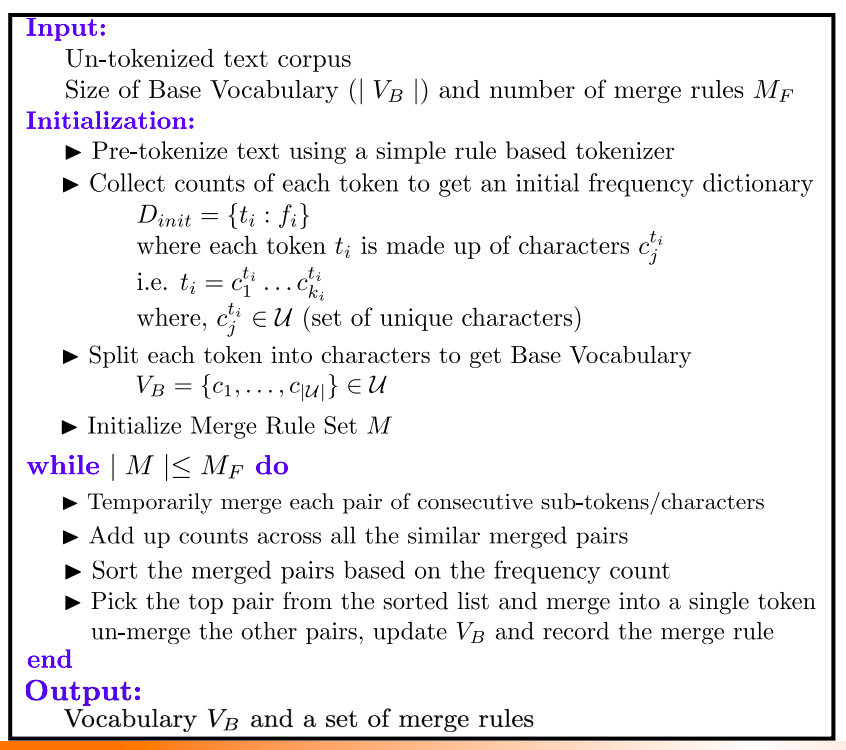

### 1.4. Reproducibility

- **Deterministic tie-breaking:**  
If two (or more) symbol pairs have the same frequency:
  - Choose the lexicographically smallest.
  - Ensure your implementation always produces the same vocabulary given the same input and vocab size.

- **Sorting vocabulary:**  
After merging, the output vocabulary should preserve:
  - The first four reserved tokens in the specified order.
  - The next tokens in the order they were first introduced by a merge, breaking ties deterministically if needed.

### 1.5. Community Impact

- BPE tokenization was pivotal for early neural machine translation (e.g., [Sennrich et al., 2015](https://arxiv.org/abs/1508.07909)
), allowing robust handling of open-vocabulary text by decomposing rare and novel words into learnable fragments.
- It became the foundation for historic models like OpenNMT, Marian, and the early versions of GPT and BERT.

***

## **2. Task Explanation [Implementation]**

**Goal:**

- Train your byte-level BPE tokenizer separately on the English corpus and the
  Hindi corpus, producing two subword vocabularies. [50 + 50 Marks]
- Tokenize each corpus using its corresponding trained tokenizer.
- Reuse your Word2vec and NNLM implementation from Questions 2 and 3 as-is (do not reimplement it) and retrain it on the subword-tokenized corpus produced above, for each language, in place of the word-level tokenized corpus used earlier. [50 + 50 Marks]

Proceed with clear, readable, well-commented code.

### Autograder Deliverables — Read Before You Start

This question (BPE Tokenization + subword-retrained NNLM) is graded
**by an autograder**, referred to as **Problem 5** in the grading
pipeline. Only the *implementation/training* part above is
autograded this way — the Analysis section below is graded separately.

**You must save and submit the following 6 files, with these exact
names** (case-sensitive, no changes):

| File | What it contains |
|---|---|
| `bpe_en.json` | Your trained English BPE tokenizer: learned merges + vocabulary |
| `bpe_hi.json` | Your trained Hindi BPE tokenizer: learned merges + vocabulary |
| `bpe_nnlm_en.pt` | Your retrained English NNLM's weights (`state_dict`) + config (`V, m, h, n, direct`) |
| `bpe_nnlm_hi.pt` | Your retrained Hindi NNLM's weights (`state_dict`) + config (`V, m, h, n, direct`) |
| `bpe_train_log_en.json` | Your English run's reported test perplexity (and train/valid history) |
| `bpe_train_log_hi.json` | Your Hindi run's reported test perplexity (and train/valid history) |

**Note the `bpe_` prefix on every file** — this is required so these files
don't clash with similarly-named files (e.g. `nnlm_en.pt`) you may already
be saving for Question 4. Do not drop the prefix.

**Suggested export code** (run this once you have `bpe_en`, `bpe_hi`, and
your retrained models/results for both languages):

```python
import json, torch

for lang, bpe, model, test_ppl, train_hist, valid_hist in [
    ("en", bpe_en, model_en, test_ppl_en, train_ppl_hist_en, valid_ppl_hist_en),
    ("hi", bpe_hi, model_hi, test_ppl_hi, train_ppl_hist_hi, valid_ppl_hist_hi),
]:
    # bpe_<lang>.json
    with open(f"bpe_{lang}.json", "w", encoding="utf-8") as f:
        json.dump({"merges": bpe.merges, "itos": bpe.itos,
                   "vocab_size": bpe.vocab_size}, f, ensure_ascii=False)

    # bpe_nnlm_<lang>.pt
    torch.save({
        "state_dict": model.state_dict(),
        "config": {"V": model.V, "m": model.m, "h": model.h,
                   "n": model.n, "direct": model.direct},
    }, f"bpe_nnlm_{lang}.pt")

    # bpe_train_log_<lang>.json
    with open(f"bpe_train_log_{lang}.json", "w", encoding="utf-8") as f:
        json.dump({"test_ppl": test_ppl, "train_ppl_history": train_hist,
                   "valid_ppl_history": valid_hist}, f)

print("Saved: bpe_en.json, bpe_hi.json, bpe_nnlm_en.pt, bpe_nnlm_hi.pt, "
      "bpe_train_log_en.json, bpe_train_log_hi.json")
```
*(Adjust the variable names above — `model_en`, `test_ppl_en`, etc. — to
whatever you actually called your retrained model and metrics. The output
**filenames must stay exactly as shown**.)*

**Submission:**
1. Put all 6 files above into a single zip named **`problem_5.zip`**.
2. Submit `problem_5.zip` **along with your `.ipynb` and the zip files for
   the other autograded questions**, as per the overall submission
   instructions.
3. Do **not** rename any of the 6 files inside the zip — the autograder
   matches on exact filenames and will not be able to find/grade files
   that don't match.

## **3. Analysis (Critical Thinking & Exploration) $20 \times 3 = 60$ Marks**

Answer the following after implementing BPE for both English and Hindi, and
after re-using your NNLM implementation from Problem 6 — retrained on the
resulting subword-tokenized corpora. Where possible, ground your answers in
numbers from your own runs rather than general claims.

**1. Perplexity.** Compare your retrained subword-level NNLM's per-word-
normalized perplexity against your word-level NNLM (Problem 6) and your
best n-gram model (Problem 3), for each language. Report the actual
numbers from your runs and explain the direction of any difference.

----------------- **write your answer here:** -----------------

**2. Embedding cosine similarity.** For words that exist as whole tokens
in both your word-level NNLM's embedding space and your subword-level
NNLM's embedding space, compute cosine similarity between the two
embeddings. Are frequent whole-word tokens more similar across the two
spaces than words that get frequently split into subwords? Explain why.

----------------- **write your answer here:** -----------------

**3. Sparsity / parameter-count observations.** Compare the vocabulary
size, embedding-table size, and total parameter count of the subword-level
NNLM against the word-level NNLM (Problem 6), for each language. How does
the change in vocabulary size affect sparsity and the number of parameters
required, and what does this imply about the trade-off between vocabulary
compactness and modeling difficulty per prediction step?

----------------- **write your answer here:** -----------------

# Submission Guidelines and Deliverables Checklist

**Notebook**
- [ ] Download this colab notebook with all your solutions and plots and save it as `CS781-A1-[Firstname]-[Lastname]-[Rollno].ipynb` (Just like your discord username)

**Question 3**

* [ ] `analogy_results_en.csv` and `analogy_results_hi.csv`
* [ ] `analogy_results_en_embedding_experiment.csv` and `analogy_results_hi_embedding_experiment.csv` (For the input embedding = output embedding experiments you did above)
* [ ] `en_embeddings_{softmax,ns,hs}.pkl`, `hi_embeddings_{softmax,ns,hs}.pkl` — each with `embeddings`, `vocab`
  (itos list), `stoi` (dict)
* [ ] `en_embeddings_{softmax,ns}_embedding_experiment.pkl`, `hi_embeddings_{softmax,ns}_embedding_experiment.pkl` — each with `embeddings`, `vocab`
  (itos list), `stoi` (dict)
* [ ] 1 timing table + 1 timing bar chart
* [ ] 2D projection scatter plots.

**Question 4**
* [ ] `analogy_results_nnlm_en.csv` and `analogy_results_nnlm_hi.csv`
* [ ] 2 convergence plots (training and validation loss per epoch), one per language
* [ ] 1 perplexity table per language, giving **NNLM**, **Laplace n-gram**, **interpolated n-gram**, **mixture at $\lambda=0.5$** and **best mixture** as separate numbers, with the best $\lambda$
* [ ] 1 parameter-count table and 1 sparsity table
* [ ] 2D projection scatter plot of the NNLM embeddings, one per language
* [ ] Written answers to all 3 questions in Step 7 and Observations

**Question 5**
* [ ] `bpe_en.json`
* [ ] `bpe_hi.json`
* [ ] `bpe_nnlm_en.pt`
* [ ] `bpe_nnlm_hi.pt`
* [ ] `bpe_train_log_en.json`
* [ ] `bpe_train_log_hi.json`
* [ ] Zip the files for question 5 into `question_5.zip`

**ZIP**
* [ ] Zip the above files into `CS781-A1-[Firstname]-[Lastname]-[Rollno].zip`